## Лабораторная работа 2. Кластерный анализ методом k-средних (k-means)

**Курс:** Анализ данных на Python

**Студент:** Муравья Никита

**Задача:** «Economics of Cities»

k-means минимизирует внутрикластерную сумму квадратов
$$J = \sum_{j=1}^{k} \sum_{x_i \in C_j} \|x_i - \mu_j\|^2, \qquad \mu_j = \frac{1}{|C_j|} \sum_{x_i \in C_j} x_i,$$
и чередует два шага: каждая точка относится к ближайшему центру, затем центры пересчитываются как средние своих кластеров.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster

sns.set(style="whitegrid", palette="Set2")
RANDOM_STATE = 42  

---
### Данные

Подготовка та же, что в работе 1: исключаем Каир и Джакарту с пропусками, остальные 46 городов стандартизуем.

In [2]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",", index_col="City")
df_raw = df_raw.replace(-9999, np.nan)
df = df_raw.dropna()
names = df.index.str.replace("_", " ")
scaler = StandardScaler()
X = scaler.fit_transform(df)
xy_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)  # только для рисунков

---
### Функции

In [3]:
def plot_clusters(xy, labels, title, xlabel, ylabel, annotate=True):
    """Рисует точки xy (n x 2) с раскраской по кластерам.

    labels   -- метки кластеров, шум DBSCAN (-1) рисуется серыми крестиками;
    annotate -- подписывать ли города (их 46, подписи читаются).
    """
    fig, ax = plt.subplots(figsize=(9, 6))
    for k in np.unique(labels):
        mask = labels == k
        if k == -1:
            ax.scatter(*xy[mask].T, c="grey", marker="x", s=60, label="шум")
        else:
            ax.scatter(*xy[mask].T, s=60, edgecolor="k", linewidth=0.5, label=f"кластер {k}")
    if annotate:
        for (x, y), name in zip(xy, names):
            ax.annotate(name, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
    plt.show()

In [4]:
def relabel(labels, by="Salary"):
    """Перенумеровывает кластеры 0, 1, ... по возрастанию среднего признака `by`.

    Номера кластеров у разных методов случайны, а так кластер 0 всегда самый
    низкооплачиваемый и разные методы удобно сравнивать. Шум (-1) не трогаем.
    """
    labels = np.asarray(labels)
    order = df[by].groupby(labels).mean().drop(-1, errors="ignore").sort_values().index
    mapping = {old: new for new, old in enumerate(order)} | {-1: -1}
    return np.array([mapping[label] for label in labels])

---
### Кластеризация k-means: выбор числа кластеров

Параметры `KMeans`:

* `init="k-means++"` (по умолчанию): начальные центры разнесены по данным;
* `n_init=20`: 20 запусков из разных стартов, берётся решение с наименьшей инерцией;
* `random_state=42`: воспроизводимость.

Перебираем $k$ от 2 до 8: при больших $k$ кластеры будут по 5 городов.

In [5]:
rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    rows.append({"k": k, "inertia": model.inertia_,
                 "silhouette": silhouette_score(X, model.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, model.labels_),
                 "davies_bouldin": davies_bouldin_score(X, model.labels_)})
scores = pd.DataFrame(rows)
scores["inertia_drop_%"] = (-scores.inertia.pct_change() * 100).round(1)
scores.round(3)

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,inertia_drop_%
0,2,61.117,0.470,55.351,0.808,NaN
1,3,47.361,0.388,41.146,0.905,22.5
2,4,35.553,0.366,40.342,1.063,24.9
3,5,27.763,0.375,40.699,0.907,21.9
4,6,23.213,0.373,39.560,0.933,16.4
5,7,18.701,0.397,41.466,0.823,19.4
6,8,15.490,0.374,42.933,0.833,17.2


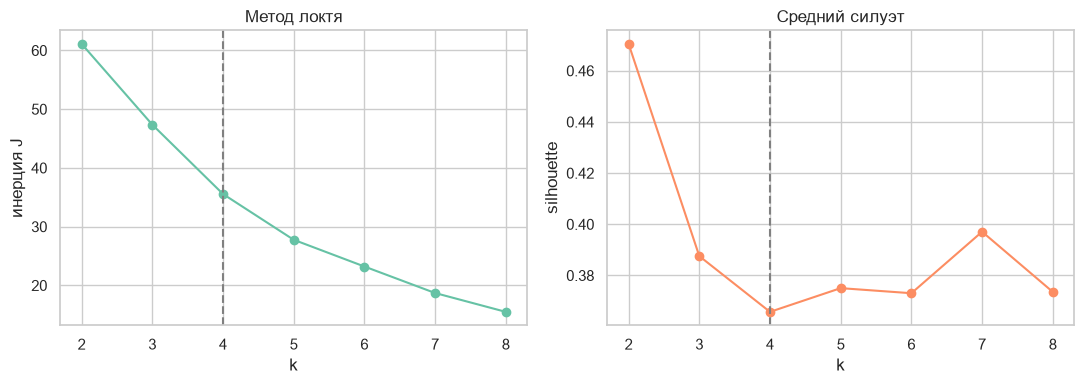

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(scores.k, scores.inertia, "o-")
axes[0].set(title="Метод локтя", xlabel="k", ylabel="инерция J")
axes[1].plot(scores.k, scores.silhouette, "o-", color="C1")
axes[1].set(title="Средний силуэт", xlabel="k", ylabel="silhouette")
for ax in axes:
    ax.axvline(4, ls="--", color="grey")
plt.tight_layout()
plt.show()

Выраженного локтя нет: инерция падает на 16–25 % на каждом шаге без резкого перелома. Все три индекса указывают на $k = 2$, но это то же деление на богатые и небогатые города, что и в работе 1. При $k = 3, \dots, 6$ силуэт держится на плато $0{,}37$–$0{,}39$. Берём **$k = 4$**: так же разрезал данные метод Уорда, и группы интерпретируются.

---
### Кластеризация k-means при k = 4

In [7]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
labels_km = relabel(km.labels_)
print("инерция:", round(km.inertia_, 2), "| итераций Ллойда:", km.n_iter_)
print("силуэт:", round(silhouette_score(X, labels_km), 3))

инерция: 35.55 | итераций Ллойда: 7
силуэт: 0.366


Центроиды в стандартизованных единицах (на сколько $\sigma$ кластер отличается от среднего города) и в исходных:

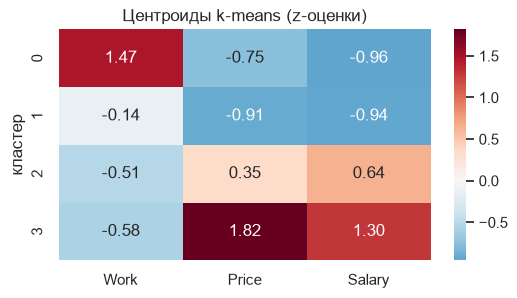

,Work,Price,Salary
0,2133.5,54.2,16.1
1,1855.5,50.8,16.6
2,1792.0,77.5,55.2
3,1780.5,108.6,71.3


In [8]:
new_label = pd.Series(labels_km).groupby(km.labels_).first()  # старая метка -> новая
centers_z = pd.DataFrame(km.cluster_centers_, columns=df.columns, index=new_label.values).sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
sns.heatmap(centers_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title="Центроиды k-means (z-оценки)", ylabel="кластер")
plt.show()
pd.DataFrame(scaler.inverse_transform(centers_z), columns=df.columns).round(1)

In [9]:
profile = df.assign(Salary_to_Price=df.Salary / df.Price).groupby(labels_km).mean().round(2)
profile.insert(0, "size", pd.Series(labels_km).value_counts().sort_index().values)
profile["cities"] = df.index.to_series().groupby(labels_km).agg(", ".join)
profile

,size,Work,Price,Salary,Salary_to_Price,cities
0,10,2133.50,54.17,16.08,0.28,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lump..."
1,11,1855.45,50.78,16.59,0.32,"Athens, Buenos_Aires, Johannesburg, Lagos, Lis..."
2,19,1792.00,77.53,55.16,0.72,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
3,6,1780.50,108.55,71.30,0.67,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"


In [10]:
silhouettes = pd.Series(silhouette_samples(X, labels_km), index=df.index)
silhouettes[silhouettes < 0].round(3)

City
Tel_Aviv   -0.029
dtype: float64

Отрицательный силуэт остался только у Тель-Авива, и тот близок к нулю.

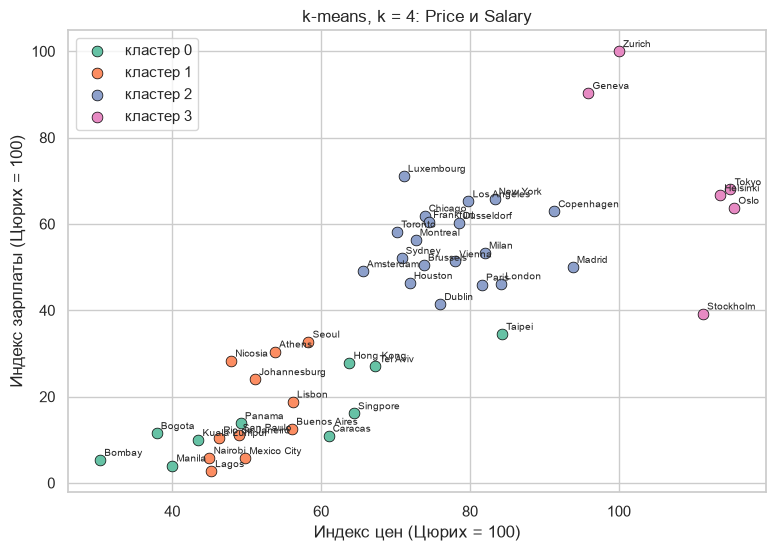

In [11]:
plot_clusters(df[["Price", "Salary"]].values, labels_km, "k-means, k = 4: Price и Salary",
              "Индекс цен (Цюрих = 100)", "Индекс зарплаты (Цюрих = 100)")

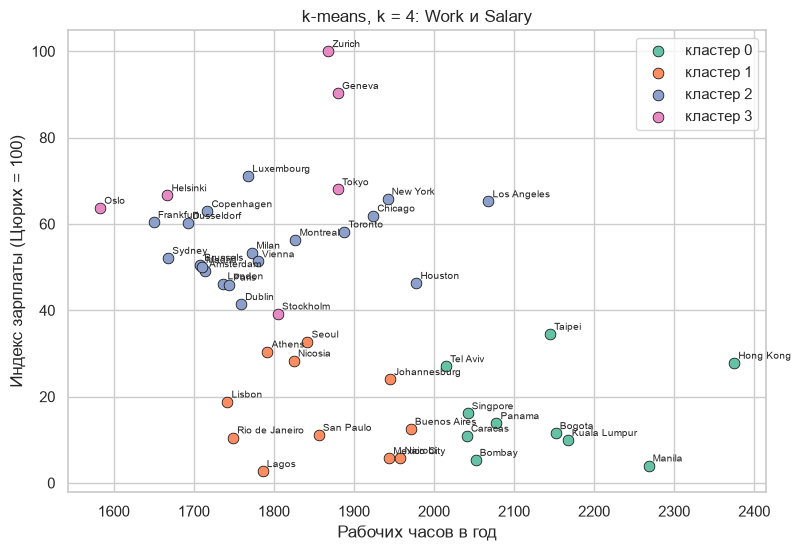

In [12]:
plot_clusters(df[["Work", "Salary"]].values, labels_km, "k-means, k = 4: Work и Salary",
              "Рабочих часов в год", "Индекс зарплаты (Цюрих = 100)")

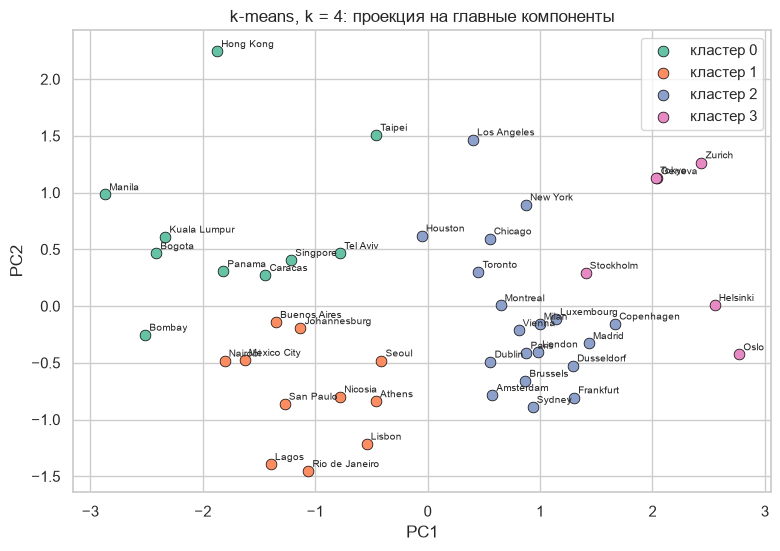

In [13]:
plot_clusters(xy_pca, labels_km, "k-means, k = 4: проекция на главные компоненты", "PC1", "PC2")

**Устойчивость.** Ллойд сходится к локальному минимуму. Запустим k-means с 20 разными `random_state` при `n_init=1` и `n_init=20` и сравним каждое разбиение с нашим по скорректированному индексу Рэнда (ARI равен 1 при совпадении с точностью до перенумерации).

In [14]:
for n_init in (1, 20):
    runs = [KMeans(n_clusters=K, n_init=n_init, random_state=seed).fit(X) for seed in range(20)]
    ari = np.array([adjusted_rand_score(labels_km, m.labels_) for m in runs])
    inertia = np.array([m.inertia_ for m in runs])
    print(f"n_init={n_init:>2}: то же разбиение в {np.mean(np.isclose(ari, 1)):.0%} запусков, "
          f"инерция {inertia.min():.2f}..{inertia.max():.2f}, ARI {ari.min():.2f}..{ari.max():.2f}")

n_init= 1: то же разбиение в 5% запусков, инерция 35.55..44.67, ARI 0.38..1.00
n_init=20: то же разбиение в 90% запусков, инерция 35.55..36.88, ARI 0.84..1.00


С одним стартом наше разбиение находится лишь в 5 % запусков, с двадцатью в 90 %. Оставшиеся два сида дают соседние локальные минимумы с чуть большей инерцией, так что `n_init=20` здесь нужен.

**Сравнение с методом Уорда** из работы 1:

In [15]:
labels_ward = relabel(fcluster(linkage(X, "ward"), K, criterion="maxclust"))
print("ARI(k-means, Ward) =", round(adjusted_rand_score(labels_km, labels_ward), 3))
display(pd.crosstab(pd.Series(labels_ward, name="Ward"), pd.Series(labels_km, name="k-means")))
moved = labels_ward != labels_km
df[moved].assign(Ward=labels_ward[moved], KMeans=labels_km[moved])

ARI(k-means, Ward) = 0.838


k-means,0,1,2,3
Ward,,,,
0,10,4,0,0
1,0,7,0,0
2,0,0,19,0
3,0,0,0,6


,Work,Price,Salary,Ward,KMeans
City,,,,,
Buenos_Aires,1971.0,56.1,12.5,0,1
Johannesburg,1945.0,51.1,24.0,0,1
Mexico_City,1944.0,49.8,5.7,0,1
Nairobi,1958.0,45.0,5.8,0,1


Кластеры 2 и 3 совпадают. Расходятся Буэнос-Айрес, Йоханнесбург, Мехико и Найроби: их рабочий год (1940–1970 часов) ближе к центру кластера 1 (1855), чем к центру кластера 0 (2134), и k-means относит их туда. Именно у трёх из них в работе 1 был отрицательный силуэт.

---
### Интерпретация

| № | Название | Размер | Work, ч | Price | Salary | Salary/Price |
|---|---|---|---|---|---|---|
| 0 | «Трудоголики развивающегося мира» | 10 | **2134** | 54 | 16 | 0,28 |
| 1 | «Дешёвая периферия» | 11 | 1855 | **51** | 17 | 0,32 |
| 2 | «Благополучный Запад» | 19 | 1792 | 78 | 55 | **0,72** |
| 3 | «Дорого и богато» | 6 | 1781 | **109** | **71** | 0,67 |

**Кластер 0:** Богота, Бомбей, Каракас, Гонконг, Куала-Лумпур, Манила, Панама, Сингапур, Тайбэй, Тель-Авив. По сравнению с работой 1 здесь остались только города с действительно длинным рабочим годом ($+1{,}5\sigma$), в основном Азия и Латинская Америка.

**Кластер 1:** Афины, Буэнос-Айрес, Йоханнесбург, Лагос, Лиссабон, Мехико, Найроби, Никосия, Рио-де-Жанейро, Сан-Паулу, Сеул. Бедные и средние экономики с обычной продолжительностью работы. От кластера 0 он отличается почти только признаком `Work`.

**Кластеры 2 и 3** те же, что в работе 1. Они различаются уровнем цен ($+0{,}35\sigma$ против $+1{,}8\sigma$).

---
### Выводы

1. Выбрано $k = 4$ при `n_init=20`; явного локтя у кривой инерции нет.
2. Разбиение почти совпадает с методом Уорда (ARI $0{,}84$), но граница между трудоголиками и периферией проходит чище.
3. Цюрих с индексами 100 и 100 сидит в кластере 3 и заметно тянет его центроид: k-means обязан отнести к кластеру каждый город, даже нетипичный.